<a href="https://colab.research.google.com/github/CorreaMartinezLuisAngel/Metodos-Numericos-I/blob/main/Diferencias_Divididas_de_Newton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<font color="lightblue"><h1><b>Diferencias divididas de Newton</b></h1></font>

<font face="Georgia" size="3" color="lightblue">
Objetivo:
</font>
<font face="Georgia" size="3">
El objetivo de este método es construir un polinomio de interpolación que reproduzca un conjunto de datos conocidos de forma incremental sin necesidad que estos se encuentren espaciados, para poder estimar valores intermedios.
</font>

<font face="Georgia" size="3" color="lightblue">
¿En qué consiste?:
</font>
<font face="Georgia" size="3">
consiste en que, a través de un conjunto de datos conocidos vas calculando cocientes de restas entre sus valores para construir un polinomio que pase exactamente por todos ellos, a partir de estos cálculos vas sumando términos conforme a cada punto para construir el polinomio y calcular así valores intermedios.
</font>

<font face="Georgia" size="3">
Estás diferencias se calculan de manera recursiva de la siguiente manera:<br>
Ceroésimas diferencias:<br>
$$f(x_i)=f[x_i]$$<br>

Primeras diferencias:<br>
$$f[x_i,x_{i+1}]=\frac {f[x_{i+1}]-f[x_i]}{x_{i+1}-x_i}$$<br>

Segundas diferencias: <br>
$$f[x_i, x_{i+1}, x_{i+2}]=\frac {f[x_{i+1}, x_{i+2}]-f[x_i, x_{i+1}]}{x_{i+2}-x_i}$$<br>

Y de esta manera de define la k-ésima diferencia dividida:<br>
$$f[x_i, x_{i+1} ,..., x_{i+k-1}, x_k]= \frac {f[x_{i+1},x_{i+2},...,x_{i+k}]-f[x_i,x_{i+1},...,x_{i+k-1}]}{x_{i+k}-x_i}$$
</font>

<font face="Georgia" size="3">
Estás cantidades nos permiten escribir el polinomio que se construye de la siguiente manera:
$$P_n(x)=f[x_0]+\sum_{k=1}^{n} f[x_0,x_1,...,x_k](x-x_0)...(x-x_{k-1})$$
</font>

<font face="Georgia" size="3">
El siguiente código es una representación de el método de diferencias divididas de Newton usando como ejemplo el ejercicio 1 de la página 94 del libro de Burden.
</font>

In [82]:
#Datos
xi=[1,1.3,1.6,1.9,2.2]
yi=[0.7651977,0.6200860,0.4554022,0.2818186,0.1103623]

In [83]:
#Metodo de diferencias divididas
def diferencias_divididas_newton(x, y):
#Cantidad de nodos
    n=len(x)-1
#Creamos una matriz para guardar los valores
    F=[[0.0 for k in range(n + 1)] for k in range(n + 1)]

#Almacenamos el valor de los f(xi)=yi
    for i in range(n + 1):
        F[i][0] = y[i]

#Calculo de las demás diferencias divididas
    for i in range(1, n + 1):
        for j in range(1, i + 1):
            F[i][j] = (F[i][j-1] - F[i-1][j-1]) / (x[i] - x[i-j])

#Almacenamos los coeficientes
    coeficientes = [F[i][i] for i in range(n + 1)]
    return coeficientes, F

#Llamamos a la función
resultado=diferencias_divididas_newton(xi, yi)

#Guardamos los coeficientes en un arreglo
coeficientes=resultado[0]

In [84]:
#Usamdo sympy para expandir y graficar

#Importamos la librería
import sympy as sp

#Añadimos símbolos
x=sp.Symbol("x")

#Inicializamos el polinomio en cero
p=0

#Usamos la función de la productoria
for k in range(len(coeficientes)):
    if k==0:
        p=p+coeficientes[k]
    else:
        p=p+coeficientes[k]*sp.prod([x-xi[m] for m in range(k)])

#Expandimos el polinomio
p=sp.expand(p)

<font face="Georgia" size="3">
Finalmente el polinomio obtenido es:
</font>

In [85]:
p

0.00182510288066044*x**4 + 0.0552927983538978*x**3 - 0.343046604938247*x**2 + 0.0733913477366034*x + 0.977735055967085

<font face="Georgia" size="3">
Y su gráfica:
</font>

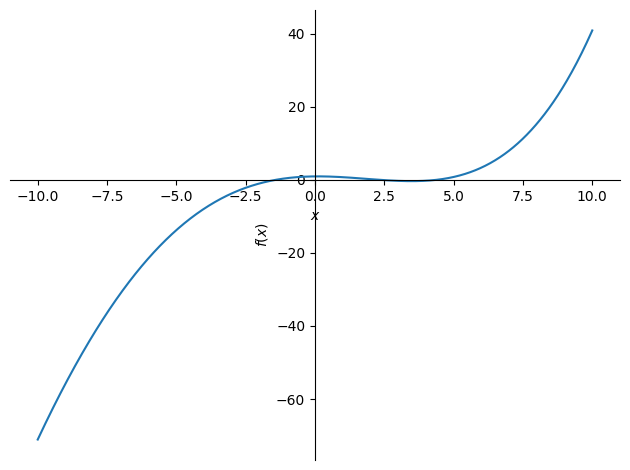

In [86]:
v=sp.plotting.plot(p)

<font face="Georgia" size="3">
Luego el polinomio evaluado en el valor que se busca es:
</font>

In [87]:
#Hacemos que p sea una función
f=sp.lambdify(x, p)

#Evaluamos en el punto que se busca aproximacion
f(1.5)

0.5118199942386829

<font face="Georgia" size="3" color="lightblue">
Conclusión:
</font>
<font face="Georgia" size="3">
El método de diferencias divididas de Newton es una forma práctica y ordenada de construir un polinomio interpolador a partir de un conjunto de puntos sin requerir nodos equidistantes aprovechando los cálculos previos que se van realizando.
</font>